In [13]:
# IMPORTS
import sys
import os
import torch
import torch.nn as nn
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from datetime import datetime as dt

import pandas, anndata, torch
print(pandas.__version__, anndata.__version__, torch.__version__)

# IMPORT OWN FILES
sys.path.append(os.path.abspath(".."))
import data_handling as dh
import binn_training as bt
from binn import BINN
import fold_prep as fp

# Supress warnings
import warnings
warnings.filterwarnings("ignore", message="Series.__getitem__ treating keys as positions", category=FutureWarning)
warnings.filterwarnings("ignore", message="The class AnnLoader is deprecated", category=FutureWarning)

3.0.6 0.13.4 2.14.0+cu130


/tmp/ipykernel_1077669/1345321289.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(pandas.__version__, anndata.__version__, torch.__version__)


In [14]:
import importlib.util
from pathlib import Path

# Determine parent folder
base_dir = Path.cwd().parent
path = base_dir / "pipeline_paths_mnt.py"

# Import module dynamically
spec = importlib.util.spec_from_file_location("ppaths", path)
ppaths = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ppaths)

# to keep consistent paths
run_vars = "mg_200_mc_200"
pp = ppaths.PipelinePaths("dev", pseudo_non_hvg_run_vars=run_vars)

base path found (/mnt/12tb_dsk3/workspaces): True
data path found (/mnt/12tb_dsk3/workspaces/isabell): True


RUNNING BINN PIPELINE FOR Inh_Exc_combined
Reading train and test data...
train_adata:
AnnData object with n_obs × n_vars = 306540 × 9766
    obs: 'projid', 'individual_ID', 'cell_type_high_resolution', 'major_cell_type', 'Pathologic_diagnosis_of_AD', 'batch', 'individualID', 'individualIdSource', 'sex', 'subject', 'Study', 'msex', 'educ', 'spanish', 'apoe_genotype_x', 'age_at_visit_max', 'age_first_ad_dx', 'age_death_x', 'cts_mmse30_first_ad_dx', 'cts_mmse30_lv', 'braaksc', 'ceradsc', 'cogdx', 'dcfdx_lv', 'clinical_diagnosis', 'pathological_diagnosis', 'clinical_pathological_AD', 'clinical_AD_Label', 'Pathological_AD_Label', 'Clinical_Pathological_AD_Label', 'pmi', 'race', 'study', 'scaled_to', 'apoe_genotype_y', 'tomm40_hap', 'synap_6_complex1', 'synap_6_complex2', 'synap_6_snap25', 'synap_6_synaptophys', 'synap_6_syntaxin', 'synap_6_vamp', 'zcapture_syn_6', 'zcomplexin_6', 'zsnare_6', 'cognep_demog_slope', 'cognep_path_slope', 'cogng_demog_slope', 'cogng_path_slope', 'cognpo_demog_s

/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Shape of pseudobulk AnnData: (133, 1000)

Nr genes in dataset 9766 -> 1000
Aggregating single-cell data to pseudobulk by mean...
Shape of pseudobulk AnnData: (34, 1000)

Standardizing data (zero mean, unit variance)...
Standardizing test data using training statistics...
Mapping 1000 genes to Reactome-paths...
Pathways pruned (unreachable or too deep): 737
Non-terminal pathways with gene conns: 1093
      ...calculating matrix for layer 0
      ...calculating matrix for layer 1
      ...calculating matrix for layer 2
      ...calculating matrix for layer 3
      ...calculating matrix for layer 4
Rolling up 'train'...
Rolling up 'test'...
Overlapping genes kept: 982 for train
Overlapping genes kept: 982 for test
No poison found!
No poison found!
Nr genes in dataset 9766 -> 1000
Aggregating single-cell data to pseudobulk by mean...
Shape of pseudobulk AnnData: (106, 1000)

Nr genes in dataset 9766 -> 1000


/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Aggregating single-cell data to pseudobulk by mean...
Shape of pseudobulk AnnData: (27, 1000)

Standardizing data (zero mean, unit variance)...
Standardizing test data using training statistics...
Mapping 1000 genes to Reactome-paths...
Pathways pruned (unreachable or too deep): 742
Non-terminal pathways with gene conns: 1099
      ...calculating matrix for layer 0


/usr/lib/python3.12/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


... (37 outputs left out)

[I 2026-11-17 22:48:17,670] A new study created in memory with name: no-name-efc24eba-fe0c-44c6-bc89-8d7153755851


input features: 982
layer list: [761, 418, 167, 29, 1]
Performing hyperparameter tuning...
Starting Optuna Hyperparameter Search...


[I 2026-11-17 22:48:25,499] Trial 0 finished with value: 0.6894949494949495 and parameters: {'lr': 6.85376842358133e-05, 'weight_decay': 0.006774144681241852, 'dropout': 0.14369125737340382}. Best is trial 0 with value: 0.6894949494949495.
[I 2026-11-17 22:48:33,227] Trial 1 finished with value: 0.7887373737373737 and parameters: {'lr': 0.009240213031079619, 'weight_decay': 0.011493837383689656, 'dropout': 0.21926534651676846}. Best is trial 1 with value: 0.7887373737373737.
[I 2026-11-17 22:48:41,040] Trial 2 finished with value: 0.7586363636363636 and parameters: {'lr': 0.0003556874510579183, 'weight_decay': 0.0002806745374461552, 'dropout': 0.13937726913012122}. Best is trial 1 with value: 0.7887373737373737.
[I 2026-11-17 22:48:48,756] Trial 3 finished with value: 0.7923737373737374 and parameters: {'lr': 0.004939500317579312, 'weight_decay': 0.00830436067875489, 'dropout': 0.18253755431938354}. Best is trial 3 with value: 0.7923737373737374.
[I 2026-11-17 22:48:56,547] Trial 4 fin

Best roc_auc: 0.8107 at epoch 24, params={'lr': 0.004139048402853372, 'weight_decay': 0.017378205031605753, 'dropout': 0.1524346827387836}
Best parameters for BINN: {'lr': 0.004139048402853372, 'weight_decay': 0.017378205031605753, 'dropout': 0.1524346827387836, 'epochs': 24, 'tune_total_epochs': 200, 'metric': 'roc_auc', 'cv_score': 0.8107323232323234}
BINN(
  (activation_fn): Tanh()
  (dropout): Dropout(p=0.1524346827387836, inplace=False)
  (model_layers): ModuleList(
    (0): Linear(in_features=982, out_features=761, bias=True)
    (1): Linear(in_features=761, out_features=418, bias=True)
    (2): Linear(in_features=418, out_features=167, bias=True)
    (3): Linear(in_features=167, out_features=29, bias=True)
    (4): Linear(in_features=29, out_features=1, bias=True)
  )
  (layer_norms): ModuleList(
    (0): LayerNorm((761,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): LayerNorm((418,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): LayerNorm((167,), eps=1e-05,

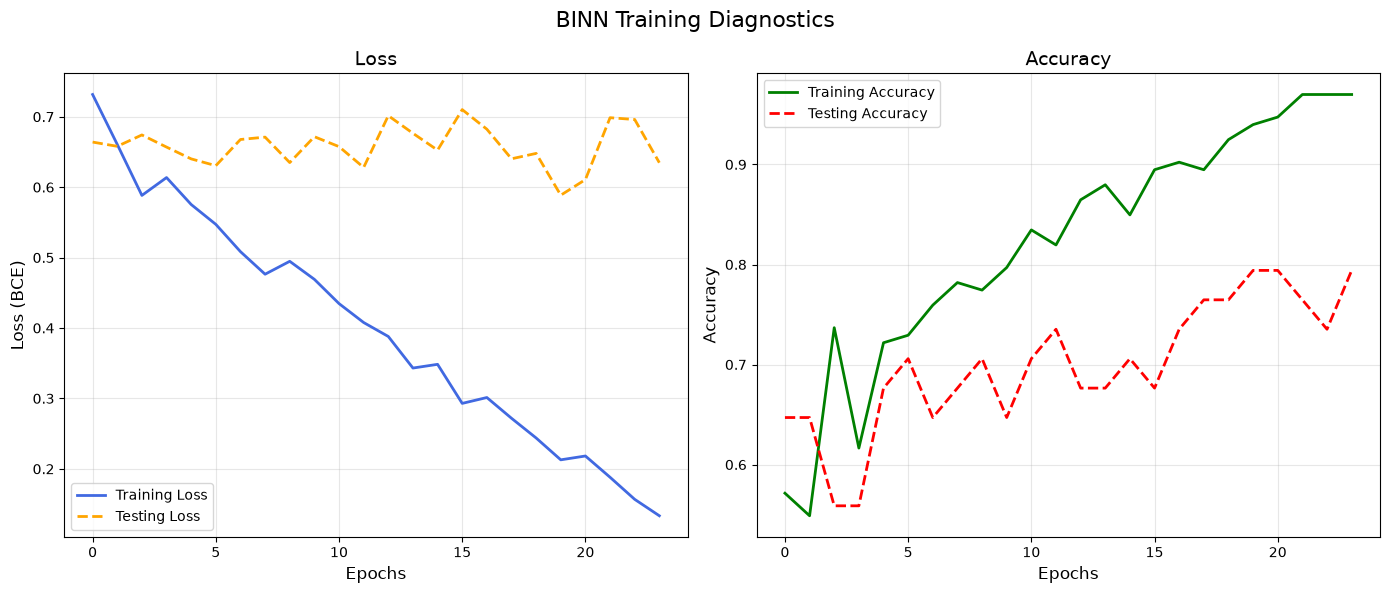

Saved: 261117_2231_binn_test_results_Inh_Exc_combined_mg_200_mc_200_1000HVGSfromCV.csv


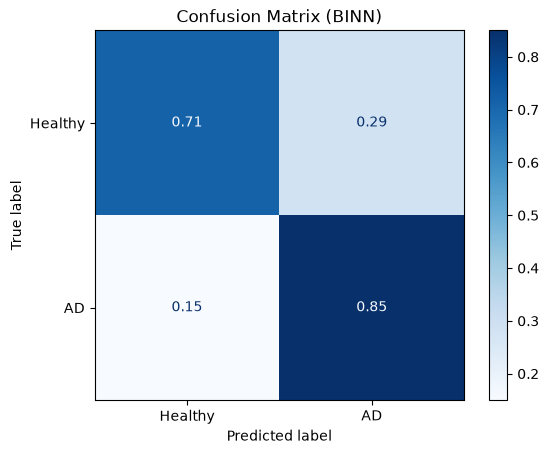

Classification report for BINN:               precision    recall  f1-score   support

         0.0       0.77      0.71      0.74        14
         1.0       0.81      0.85      0.83        20

    accuracy                           0.79        34
   macro avg       0.79      0.78      0.79        34
weighted avg       0.79      0.79      0.79        34

              precision    recall  f1-score   support

         0.0       0.77      0.71      0.74        14
         1.0       0.81      0.85      0.83        20

    accuracy                           0.79        34
   macro avg       0.79      0.78      0.79        34
weighted avg       0.79      0.79      0.79        34

COMPLETED BINN PIPELINE FOR Inh_Exc_combined 





,eval_metric,nested_cv_mean,nested_cv_std,outer_epochs,final_epochs
Inh_Exc_combined,roc_auc,0.725328,0.099253,"[149, 135, 72, 90, 91]",24


In [ ]:
# GLOBALS
TRAIN_SIZE = 0.8
BATCH_SIZE = 32
MAX_EPOCHS = 200
FOLDS_OUTER = 5
FOLDS_INNER = 5
N_TRIALS = 30
EVAL_METRIC = 'roc_auc'
N_HVGS = 1000
N_LAYERS = 4

# PARAMETERS
LR = 0.002204
WEIGHT_DECAY = 0.021469
DROPOUT = 0.176345
ACTIVATION_FN = nn.Tanh()

# PATHS
data_path = pp.compl_hvg_from_cv

# OTHER
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TUNE_HYPERPARAMETERS = True

now = dt.now().strftime("%y%m%d_%H%M")
if TUNE_HYPERPARAMETERS:
    now_hyper = now
else:
    # hyperparameters to read
    now_hyper = '261110_0958'

cell_types = ['all_cells_combined']

all_results = {}
for cell_type in cell_types:
    print(f'RUNNING BINN PIPELINE FOR {cell_type}')
    data_info = f'{cell_type}_{run_vars}_{N_HVGS}HVGSfromCV'
    HPARAM_PATH = pp.binn_model_path / f"{now_hyper}_best_hyperparameters_{data_info}.json"

    print("Reading train and test data...")
    train_adata = ad.read_h5ad(data_path / f'{cell_type}_train_preprocessed_noHVG.h5ad')
    test_adata = ad.read_h5ad(data_path / f'{cell_type}_test_preprocessed_noHVG.h5ad')

    print(f'train_adata:\n{train_adata}')

    conns = fp.load_pathway_conns(pp.pathway_data_path / 'binn_connectivity.csv')

    data, masks, artifacts = fp.preprocess_split(
        train_adata,
        {'test': test_adata},
        N_HVGS,
        conns,
        N_LAYERS
    )

    train_loader, test_loader = dh.create_dataloaders(
        data['train'], data['test'], batch_size=BATCH_SIZE)

    dh.poison_scanner(train_loader, device)
    dh.poison_scanner(test_loader, device)
    
    # CROSS VALIDATION
    outer_scores, outer_params = fp.run_CV_nested_HVG_sel(
        train_adata,                           
        device,
        eval_metric=EVAL_METRIC,
        conns=conns,
        n_hvgs=N_HVGS,
        n_layers=N_LAYERS,
        k_outer=FOLDS_OUTER,
        k_inner=FOLDS_INNER,
        epochs=MAX_EPOCHS,
        n_trials=N_TRIALS,
        activation_fn=ACTIVATION_FN,
        save_path=pp.binn_model_path,
        data_info=data_info,
        time=now
        )
    
    # save masks
    mask_dir = pp.mask_hvg_from_cv / run_vars
    mask_dir.mkdir(parents=True, exist_ok=True)
    for i, (name, m) in enumerate(masks.items()):
        m.to_csv(mask_dir / f"{cell_type}_train_preprocessed_layer_{i}_mask.csv")

    # save processed datasets
    for split, a in data.items():
        a.write_h5ad(pp.compl_hvg_from_cv / f"{cell_type}_{split}_preprocessed.h5ad")

    # save HVGs also as plain text, readable without Python
    pd.Series(artifacts['hvgs'], name='gene').to_csv(
    pp.binn_model_path / f"{now}_hvgs_{data_info}.csv", index=False)

    _, in_features, layers_list, tensor_masks = dh.compute_features(masks, device)

    # Hyperparameter tuning
    print("Performing hyperparameter tuning...")
    final = dh.hyperparameter_tuning_optuna(
        data['train'], 
        in_features, 
        layers_list, 
        tensor_masks, 
        device, 
        batch_size=BATCH_SIZE, 
        activation_fn=ACTIVATION_FN,
        k=FOLDS_INNER, 
        epochs=MAX_EPOCHS,
        metric=EVAL_METRIC
        )
    print(f"Best parameters for BINN: {final}")
    dh.save_hyperparameters(final, HPARAM_PATH)

    artifact_path = pp.binn_model_path / f"{now}_artifacts_{data_info}.joblib"
        
    joblib.dump({
        **artifacts,
        'n_hvgs': N_HVGS,
        'n_layers': N_LAYERS,
        'eval_metric': EVAL_METRIC,
        'hparams': final,
        'run_vars': run_vars,
        'time': now,
        }, artifact_path)


    # model is MLP with same layers as BINN 
    binn, criterion, optimizer, scheduler = dh.create_model(
        in_features, 
        layers_list, 
        tensor_masks, 
        device, 
        lr=final["lr"], 
        weight_decay=final["weight_decay"], 
        dropout=final["dropout"], 
        epochs=final['tune_total_epochs'],
        activation_fn=ACTIVATION_FN
        )
    print(binn)

    print(f"criterion: {criterion},\n optimizer: {optimizer}")

    # Run it
    dead_nodes_dict = dh.find_dead_outputs(binn, tensor_masks)
    print(dead_nodes_dict)

    # Dead output
    dh.show_dead_nodes(dead_nodes_dict, masks)

    for batch in train_loader:
        print(batch.X)
        break

    history = dh.train_fixed_epochs(
            binn, 
            train_loader, 
            criterion=criterion, 
            optimizer=optimizer, 
            scheduler=scheduler, 
            device=device,
            n_epochs=final['epochs'],
            save_path=pp.binn_model_path,
            data_info=data_info,
            time=now,
            monitor_loader=test_loader
            )

    # Harvest the results
    probs, targets, test_auc = dh.evaluate_model_roc(binn, test_loader, device)
    print(f"Test ROC-AUC: {test_auc:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    # Loss plot
    axes[0].plot(history['train_loss'], label='Training Loss', color='royalblue', linewidth=2)
    axes[0].plot(history['test_loss'], label='Testing Loss', color='orange', linestyle='--', linewidth=2)
    axes[0].set_title('Loss', fontsize=14)
    axes[0].set_xlabel('Epochs', fontsize=12)
    axes[0].set_ylabel('Loss (BCE)', fontsize=12)
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy plot
    axes[1].plot(history['train_acc'], label='Training Accuracy', color='green', linewidth=2)
    axes[1].plot(history['test_acc'], label='Testing Accuracy', color='red', linestyle='--', linewidth=2)
    axes[1].set_title('Accuracy', fontsize=14)
    axes[1].set_xlabel('Epochs', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.suptitle('BINN Training Diagnostics', fontsize=16)
    plt.tight_layout()
    fig.savefig(pp.binn_test_results_path / f'{now}_training_curves_{data_info}.png')
    plt.show()

    df_res = dh.save_test_results(
        binn, 
        test_loader, 
        device, 
        data_info, 
        pp.binn_test_results_path,
        now
        )
    
    dh.confusion_matrix_binn(df_res, pp.binn_test_results_path, data_info, now)

    report = dh.class_report(df_res)
    print(report)

    all_results[cell_type] = {
        'eval_metric': EVAL_METRIC,
        'nested_cv_mean': np.mean(outer_scores), 
        'nested_cv_std': np.std(outer_scores),
        'outer_epochs': [p['epochs'] for p in outer_params], 
        'final_epochs': final['epochs'],
    }
    
    pd.DataFrame(history).to_csv(
        pp.binn_model_path/ f'{now}_history_{data_info}.csv', 
        index_label='epoch')
    
    with open(pp.binn_test_results_path / f'{now}_class_report_{data_info}.txt', 'w') as f:
        f.write(report)

    print(f'COMPLETED BINN PIPELINE FOR {cell_type} \n\n\n')

summary = pd.DataFrame(all_results).T
summary.to_csv(pp.binn_test_results_path / f'{now}_summary_{run_vars}.csv')
summary

